In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("Running on CPU")

GPU available: True
GPU name: Tesla T4
GPU memory: 14.56 GB


In [2]:
%pip install -q transformers==4.51.3 datasets==3.5.0 peft==0.15.2 trl==0.17.0 accelerate==1.6.0 bitsandbytes==0.45.5

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
pathos 0.3.5 requires dill>=0.4.1, but you have dill 0.3.8 which is incompatible.
pathos 0.3.5 requires multiprocess>=0.70.19, but you have multiprocess 0.70.16 which is incompatible.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.12.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,

In [3]:
import torch
import transformers
import datasets
import peft
import trl
import accelerate
import bitsandbytes

from trl import SFTTrainer, SFTConfig
from peft import LoraConfig

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("Accelerate:", accelerate.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)

print("\nGPU available:", torch.cuda.is_available())
print("\nAll required libraries imported successfully!")

I0000 00:00:1795511438.880645      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


PyTorch: 2.11.0+cu130
Transformers: 4.51.3
Datasets: 3.5.0
PEFT: 0.15.2
TRL: 0.17.0
Accelerate: 1.6.0
BitsAndBytes: 0.45.5

GPU available: True

All required libraries imported successfully!


In [4]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_NAME = "HuggingFaceTB/SmolLM2-360M-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
).to("cuda")

print("Model loaded successfully!")
print("Model:", MODEL_NAME)
print("Device:", next(model.parameters()).device)
print(f"Total parameters: {model.num_parameters():,}")
print(f"GPU memory allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/724M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Model loaded successfully!
Model: HuggingFaceTB/SmolLM2-360M-Instruct
Device: cuda:0
Total parameters: 361,821,120
GPU memory allocated: 0.69 GB


In [5]:

import json
from pathlib import Path
from datasets import Dataset

OUTPUT_DIR = Path("/kaggle/working/lab04-results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

qa_pairs = [
    ("What is your shop name?", "Our shop is called TechNova Computers."),
    ("Where is your shop located?", "TechNova Computers is located in Colombo, Sri Lanka."),
    ("What are your opening hours?", "We are open from 9 AM to 7 PM, Monday to Saturday."),
    ("Are you open on Sundays?", "No, TechNova Computers is closed on Sundays."),
    ("Do you sell laptops?", "Yes, we sell laptops for students, professionals and gamers."),
    ("Do you sell desktop computers?", "Yes, we offer prebuilt and custom desktop computers."),
    ("Do you sell gaming computers?", "Yes, we offer gaming computers for different budgets."),
    ("Can I customize my PC?", "Yes, we provide custom PC building services."),
    ("Do you offer delivery?", "Yes, TechNova Computers provides islandwide delivery."),
    ("How much is delivery in Colombo?", "Delivery within Colombo costs LKR 500."),
    ("How much is delivery outside Colombo?", "Delivery outside Colombo costs LKR 1000."),
    ("How long does delivery take?", "Delivery usually takes two to four working days."),
    ("Do you accept cash payments?", "Yes, we accept cash payments."),
    ("Do you accept card payments?", "Yes, we accept Visa and Mastercard payments."),
    ("Can I pay by bank transfer?", "Yes, bank transfers are accepted."),
    ("Do you offer installment plans?", "Yes, installment plans are available through selected banks."),
    ("What is your laptop warranty?", "All new laptops include a two-year warranty."),
    ("What is your desktop warranty?", "Desktop computers include a one-year warranty."),
    ("What is your accessory warranty?", "Computer accessories include a six-month warranty."),
    ("What is your return policy?", "Unused products can be returned within seven days with the original receipt."),
    ("Can I return a damaged product?", "Manufacturing defects are handled through our warranty service."),
    ("Do you repair laptops?", "Yes, we provide laptop repair services."),
    ("Do you repair desktop computers?", "Yes, we diagnose and repair desktop computers."),
    ("How much is a diagnostic check?", "A standard diagnostic check costs LKR 1500."),
    ("Do you install operating systems?", "Yes, we provide operating system installation services."),
    ("Do you upgrade RAM?", "Yes, we provide compatible RAM upgrades."),
    ("Can you install an SSD?", "Yes, we install SATA and NVMe SSDs."),
    ("Do you clean computers?", "Yes, we provide internal computer cleaning services."),
    ("How much is laptop cleaning?", "Standard laptop cleaning costs LKR 2500."),
    ("How much is desktop cleaning?", "Standard desktop cleaning costs LKR 3000."),
    ("Do you replace thermal paste?", "Yes, thermal paste replacement is available."),
    ("Do you sell monitors?", "Yes, we sell office and gaming monitors."),
    ("Do you sell keyboards?", "Yes, we sell mechanical and membrane keyboards."),
    ("Do you sell gaming mice?", "Yes, gaming mice are available."),
    ("Do you sell graphics cards?", "Yes, we sell NVIDIA and AMD graphics cards."),
    ("Do you sell processors?", "Yes, we sell Intel and AMD processors."),
    ("Do you sell motherboards?", "Yes, we offer compatible Intel and AMD motherboards."),
    ("Do you sell power supplies?", "Yes, we offer power supplies with different wattage ratings."),
    ("Do you sell computer cases?", "Yes, we sell computer cases in multiple sizes."),
    ("Do you sell refurbished laptops?", "No, TechNova Computers only sells new laptops."),
    ("Do you offer student discounts?", "Yes, students receive a five percent discount with a valid student ID."),
    ("Do you offer business discounts?", "Yes, business discounts are available for bulk purchases."),
    ("Can I reserve a product?", "Yes, products can be reserved for 48 hours."),
    ("Do you provide invoices?", "Yes, every purchase includes an official invoice."),
    ("Can I track my order?", "Yes, customers receive a tracking number after dispatch."),
    ("Do you offer technical support?", "Yes, technical support is available during business hours."),
    ("Do you recover lost data?", "Yes, we provide basic data recovery services."),
    ("Can I exchange my old laptop?", "No, TechNova Computers does not currently offer trade-in services."),
    ("Do custom computers require an advance?", "Yes, custom PC orders require a 20 percent advance payment."),
    ("How long does a custom PC build take?", "Custom PC builds usually take three to five working days.")
]

records = [
    {"question": question, "answer": answer}
    for question, answer in qa_pairs
]

dataset = Dataset.from_list(records)

dataset_path = OUTPUT_DIR / "computer_shop_qa.jsonl"

with open(dataset_path, "w", encoding="utf-8") as f:
    for record in records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Dataset created successfully!")
print("Total question-answer pairs:", len(dataset))
print("Dataset saved to:", dataset_path)

display(dataset.to_pandas().head(10))


Dataset created successfully!
Total question-answer pairs: 50
Dataset saved to: /kaggle/working/lab04-results/computer_shop_qa.jsonl


,question,answer
0,What is your shop name?,Our shop is called TechNova Computers.
1,Where is your shop located?,"TechNova Computers is located in Colombo, Sri ..."
2,What are your opening hours?,"We are open from 9 AM to 7 PM, Monday to Satur..."
3,Are you open on Sundays?,"No, TechNova Computers is closed on Sundays."
4,Do you sell laptops?,"Yes, we sell laptops for students, professiona..."
5,Do you sell desktop computers?,"Yes, we offer prebuilt and custom desktop comp..."
6,Do you sell gaming computers?,"Yes, we offer gaming computers for different b..."
7,Can I customize my PC?,"Yes, we provide custom PC building services."
8,Do you offer delivery?,"Yes, TechNova Computers provides islandwide de..."
9,How much is delivery in Colombo?,Delivery within Colombo costs LKR 500.


In [6]:

import pandas as pd

SYSTEM_PROMPT = "You are a helpful customer service assistant for TechNova Computers."

test_questions = [
    ("How long is the warranty on a new notebook computer?", "Two years"),
    ("What is the shipping fee within Colombo?", "LKR 500"),
    ("Can university students get a discount?", "Five percent with a valid student ID"),
    ("What percentage must I pay upfront for a custom PC?", "20 percent"),
    ("How many days do I have to return an unused item?", "Seven days with the original receipt")
]

def generate_response(current_model, question):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    ).to(next(current_model.parameters()).device)

    current_model.eval()

    with torch.no_grad():
        outputs = current_model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id
        )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return response.strip()

baseline_results = []

for question, expected in test_questions:
    response = generate_response(model, question)

    baseline_results.append({
        "question": question,
        "expected_answer": expected,
        "original_response": response
    })

    print("Question:", question)
    print("Expected:", expected)
    print("Original model:", response)
    print("-" * 70)

baseline_df = pd.DataFrame(baseline_results)

baseline_df.to_csv(
    OUTPUT_DIR / "baseline_responses.csv",
    index=False
)

print("Baseline evaluation completed!")


Question: How long is the warranty on a new notebook computer?
Expected: Two years
Original model: The warranty on a new notebook computer from TechNova Computers typically lasts for 24 months from the date of purchase. However, it's always best to check the warranty details on the product's packaging or contact TechNova Computers directly for the most accurate information.
----------------------------------------------------------------------
Question: What is the shipping fee within Colombo?
Expected: LKR 500
Original model: As an AI, I don't have real-time access to current shipping rates or prices. I recommend checking the official website of Colombo's shipping provider or contacting them directly for the most accurate and up-to-date information.
----------------------------------------------------------------------
Question: Can university students get a discount?
Expected: Five percent with a valid student ID
Original model: As an AI, I don't have real-time access to current disc

In [7]:

from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

model = get_peft_model(model, lora_config)

model.config.use_cache = False

print("LoRA configuration completed!")
model.print_trainable_parameters()


LoRA configuration completed!
trainable params: 8,683,520 || all params: 370,504,640 || trainable%: 2.3437


In [8]:

def format_training_example(example):
    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": example["question"]
        },
        {
            "role": "assistant",
            "content": example["answer"]
        }
    ]

    return {
        "text": tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False
        )
    }

training_dataset = dataset.map(
    format_training_example,
    remove_columns=dataset.column_names
)

print("Training dataset prepared successfully!")
print("Total training examples:", len(training_dataset))

print("\nSample formatted training example:\n")
print(training_dataset[0]["text"])


Map:   0%|          | 0/50 [00:00<?, ? examples/s]

Training dataset prepared successfully!
Total training examples: 50

Sample formatted training example:

<|im_start|>system
You are a helpful customer service assistant for TechNova Computers.<|im_end|>
<|im_start|>user
What is your shop name?<|im_end|>
<|im_start|>assistant
Our shop is called TechNova Computers.<|im_end|>



In [9]:
import torch

print("GPU available:", torch.cuda.is_available())
print("Model loaded:", "model" in globals())
print("Dataset available:", "dataset" in globals())
print("Training dataset available:", "training_dataset" in globals())
print("LoRA configured:", "lora_config" in globals())

GPU available: True
Model loaded: True
Dataset available: True
Training dataset available: True
LoRA configured: True


In [14]:

import torch
import gc

from transformers import Trainer
from trl import SFTTrainer, SFTConfig

# Clear the previous trainer
if "trainer" in globals():
    del trainer

gc.collect()
torch.cuda.empty_cache()
model.zero_grad(set_to_none=True)

# Bypass TRL's problematic token accuracy calculation
class CompatibleSFTTrainer(SFTTrainer):
    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        return Trainer.compute_loss(
            self,
            model,
            inputs,
            return_outputs=return_outputs,
            num_items_in_batch=num_items_in_batch
        )

training_args = SFTConfig(
    output_dir=str(OUTPUT_DIR / "checkpoints"),
    num_train_epochs=10,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=1,
    learning_rate=2e-4,
    logging_steps=5,
    save_strategy="epoch",
    save_total_limit=2,
    optim="adamw_torch",
    lr_scheduler_type="cosine",
    warmup_ratio=0.05,
    fp16=True,
    bf16=False,
    max_grad_norm=1.0,
    max_seq_length=256,
    dataset_text_field="text",
    packing=False,
    label_names=["labels"],
    report_to="none",
    seed=42
)

trainer = CompatibleSFTTrainer(
    model=model,
    args=training_args,
    train_dataset=training_dataset,
    processing_class=tokenizer
)

print("Compatible SFTTrainer configured successfully!")
print("Available GPUs:", torch.cuda.device_count())


Converting train dataset to ChatML:   0%|          | 0/50 [00:00<?, ? examples/s]

Adding EOS to train dataset:   0%|          | 0/50 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/50 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/50 [00:00<?, ? examples/s]

Compatible SFTTrainer configured successfully!
Available GPUs: 2


In [15]:

import time

torch.cuda.reset_peak_memory_stats()

print("Starting LoRA fine-tuning...\n")

start_time = time.time()

train_result = trainer.train()

training_duration = time.time() - start_time

print("\nFine-tuning completed successfully!")
print(f"Training duration: {training_duration:.2f} seconds")
print(f"Training duration: {training_duration / 60:.2f} minutes")
print(f"Final training loss: {train_result.training_loss:.4f}")
print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")


Starting LoRA fine-tuning...



Step,Training Loss
5,1.152600
10,0.839600
15,0.577600
20,0.449500
25,0.330500
30,0.275900
35,0.356000
40,0.306200
45,0.236000
50,0.175500



Fine-tuning completed successfully!
Training duration: 49.30 seconds
Training duration: 0.82 minutes
Final training loss: 0.2925
Peak GPU memory: 2.39 GB


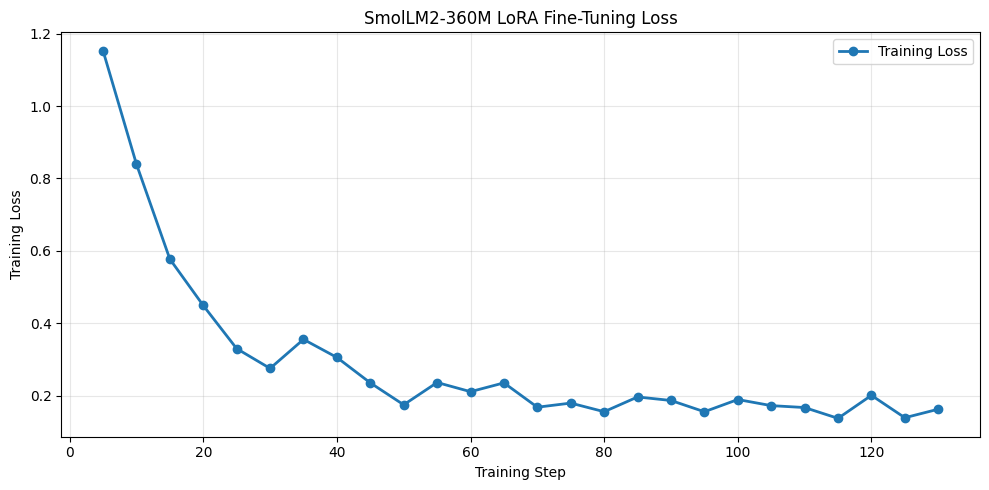

Training history and loss graph saved successfully!


In [16]:

import pandas as pd
import matplotlib.pyplot as plt

training_history = pd.DataFrame([
    log for log in trainer.state.log_history
    if "loss" in log
])

training_history.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

plt.figure(figsize=(10, 5))

plt.plot(
    training_history["step"],
    training_history["loss"],
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.title("SmolLM2-360M LoRA Fine-Tuning Loss")
plt.xlabel("Training Step")
plt.ylabel("Training Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training history and loss graph saved successfully!")


In [17]:

adapter_path = OUTPUT_DIR / "lora_adapter"

model.save_pretrained(adapter_path)
tokenizer.save_pretrained(adapter_path)

model.config.use_cache = True
model.eval()

print("Fine-tuned LoRA adapters saved successfully!")
print("Saved location:", adapter_path)


Fine-tuned LoRA adapters saved successfully!
Saved location: /kaggle/working/lab04-results/lora_adapter


In [18]:

comparison_results = []

for result in baseline_results:

    question = result["question"]
    expected = result["expected_answer"]
    original_response = result["original_response"]

    fine_tuned_response = generate_response(
        model,
        question
    )

    comparison_results.append({
        "question": question,
        "expected_answer": expected,
        "original_response": original_response,
        "fine_tuned_response": fine_tuned_response
    })

    print("Question:", question)
    print("Expected:", expected)
    print("\nOriginal model:", original_response)
    print("\nFine-tuned model:", fine_tuned_response)
    print("=" * 80)

comparison_df = pd.DataFrame(comparison_results)

comparison_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully!")


Question: How long is the warranty on a new notebook computer?
Expected: Two years

Original model: The warranty on a new notebook computer from TechNova Computers typically lasts for 24 months from the date of purchase. However, it's always best to check the warranty details on the product's packaging or contact TechNova Computers directly for the most accurate information.

Fine-tuned model: The laptop computer warranty is valid for 12 months.
Question: What is the shipping fee within Colombo?
Expected: LKR 500

Original model: As an AI, I don't have real-time access to current shipping rates or prices. I recommend checking the official website of Colombo's shipping provider or contacting them directly for the most accurate and up-to-date information.

Fine-tuned model: Standard shipping within Colombo costs LKR 1000.
Question: Can university students get a discount?
Expected: Five percent with a valid student ID

Original model: As an AI, I don't have real-time access to current dis

In [19]:
training_test_indices = [16, 9, 40, 48, 19]

for index in training_test_indices:
    question, expected = qa_pairs[index]

    response = generate_response(model, question)

    print("Question:", question)
    print("Expected:", expected)
    print("Fine-tuned:", response)
    print("-" * 80)

Question: What is your laptop warranty?
Expected: All new laptops include a two-year warranty.
Fine-tuned: Our laptop warranty is valid for 36 months.
--------------------------------------------------------------------------------
Question: How much is delivery in Colombo?
Expected: Delivery within Colombo costs LKR 500.
Fine-tuned: Delivery costs LKR 1000.
--------------------------------------------------------------------------------
Question: Do you offer student discounts?
Expected: Yes, students receive a five percent discount with a valid student ID.
Fine-tuned: Yes, students receive a 10% discount on all purchases.
--------------------------------------------------------------------------------
Question: Do custom computers require an advance?
Expected: Yes, custom PC orders require a 20 percent advance payment.
Fine-tuned: Yes, custom computers require an advance payment of 10% of the total cost.
--------------------------------------------------------------------------------

In [20]:
import shutil
from pathlib import Path

EXPERIMENT_1_DIR = Path(
    "/kaggle/working/experiment_1"
)

shutil.copytree(
    OUTPUT_DIR,
    EXPERIMENT_1_DIR,
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns("checkpoints")
)

print("Experiment 1 backed up successfully!")

for file in EXPERIMENT_1_DIR.iterdir():
    print(file.name)

Experiment 1 backed up successfully!
model_comparison.csv
computer_shop_qa.jsonl
baseline_responses.csv
training_loss.png
training_history.csv
lora_adapter


In [21]:

import json
from pathlib import Path
from datasets import Dataset

EXPERIMENT_2_DIR = Path("/kaggle/working/experiment_2")
EXPERIMENT_2_DIR.mkdir(parents=True, exist_ok=True)

question_templates = [
    "{}",
    "Could you please tell me: {}",
    "I would like to know: {}",
    "As a customer, I want to ask: {}",
    "Regarding TechNova Computers, {}"
]

expanded_records = []

for question, answer in qa_pairs:
    for template in question_templates:
        expanded_records.append({
            "question": template.format(question),
            "answer": answer
        })

# Replace generic variations for important shop policies
policy_variations = {
    16: [
        "What is your laptop warranty?",
        "What warranty period applies to laptops?",
        "How many years are laptops covered under warranty?",
        "What warranty comes with a new laptop?",
        "How long does your laptop warranty last?"
    ],
    9: [
        "How much is delivery in Colombo?",
        "What does Colombo delivery cost?",
        "What do you charge for local delivery?",
        "How much do Colombo customers pay for delivery?",
        "What is the delivery charge for Colombo orders?"
    ],
    40: [
        "Do you offer student discounts?",
        "What discount is available for students?",
        "How much can students save?",
        "Is there a special discount for students?",
        "What is your student discount policy?"
    ],
    48: [
        "Do custom computers require an advance?",
        "What is the deposit for a custom computer?",
        "How much is the advance for a custom build?",
        "What is your custom computer deposit policy?",
        "Is an initial payment required for custom builds?"
    ],
    19: [
        "What is your return policy?",
        "What is the allowed product return period?",
        "How long is your product return window?",
        "When can customers return unused products?",
        "What are the conditions for returning products?"
    ]
}

for index, variations in policy_variations.items():
    answer = qa_pairs[index][1]

    for offset, question in enumerate(variations):
        expanded_records[index * 5 + offset] = {
            "question": question,
            "answer": answer
        }

# Verify evaluation questions are not included
test_question_set = {
    question.strip().lower()
    for question, expected in test_questions
}

assert not any(
    record["question"].strip().lower() in test_question_set
    for record in expanded_records
), "Evaluation question found in training dataset!"

expanded_dataset = Dataset.from_list(
    expanded_records
).shuffle(seed=42)

dataset_path = EXPERIMENT_2_DIR / "computer_shop_qa_expanded.jsonl"

with open(dataset_path, "w", encoding="utf-8") as f:
    for record in expanded_records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Expanded dataset created successfully!")
print("Original examples:", len(qa_pairs))
print("Expanded examples:", len(expanded_dataset))
print("Evaluation question overlap: None")
print("Dataset saved to:", dataset_path)

display(expanded_dataset.to_pandas().head(10))


Expanded dataset created successfully!
Original examples: 50
Expanded examples: 250
Evaluation question overlap: None
Dataset saved to: /kaggle/working/experiment_2/computer_shop_qa_expanded.jsonl


,question,answer
0,Do you install operating systems?,"Yes, we provide operating system installation ..."
1,How much is delivery outside Colombo?,Delivery outside Colombo costs LKR 1000.
2,"Regarding TechNova Computers, How much is deli...",Delivery outside Colombo costs LKR 1000.
3,What does Colombo delivery cost?,Delivery within Colombo costs LKR 500.
4,How long does a custom PC build take?,Custom PC builds usually take three to five wo...
5,Do you clean computers?,"Yes, we provide internal computer cleaning ser..."
6,Could you please tell me: Do you sell graphics...,"Yes, we sell NVIDIA and AMD graphics cards."
7,"As a customer, I want to ask: What is your sho...",Our shop is called TechNova Computers.
8,What is your student discount policy?,"Yes, students receive a five percent discount ..."
9,Could you please tell me: Can I track my order?,"Yes, customers receive a tracking number after..."


In [22]:

import gc
import torch

from transformers import AutoModelForCausalLM
from peft import get_peft_model

# Release the previous model and trainer
if "trainer" in globals():
    del trainer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

# Load a fresh pretrained model
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
).to("cuda")

# Apply fresh LoRA adapters
model = get_peft_model(model, lora_config)
model.config.use_cache = False

print("Fresh pretrained model loaded successfully!")
print("New LoRA adapters initialized!")
model.print_trainable_parameters()

print(
    f"GPU memory allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)



Fresh pretrained model loaded successfully!
New LoRA adapters initialized!
trainable params: 8,683,520 || all params: 370,504,640 || trainable%: 2.3437
GPU memory allocated: 1.70 GB


In [23]:

def tokenize_assistant_only(example):

    prompt_messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": example["question"]}
    ]

    full_messages = prompt_messages + [
        {"role": "assistant", "content": example["answer"]}
    ]

    prompt_ids = tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=True,
        add_generation_prompt=True
    )

    full_ids = tokenizer.apply_chat_template(
        full_messages,
        tokenize=True,
        add_generation_prompt=False
    )

    prompt_length = len(prompt_ids)

    assert full_ids[:prompt_length] == prompt_ids

    labels = (
        [-100] * prompt_length
        + full_ids[prompt_length:]
    )

    return {
        "input_ids": full_ids,
        "attention_mask": [1] * len(full_ids),
        "labels": labels
    }

masked_dataset = expanded_dataset.map(
    tokenize_assistant_only,
    remove_columns=expanded_dataset.column_names
)

sample = masked_dataset[0]

active_labels = [
    token for token in sample["labels"]
    if token != -100
]

print("Assistant-only dataset prepared successfully!")
print("Total training examples:", len(masked_dataset))

print("\nTotal tokens:", len(sample["input_ids"]))
print("Masked tokens:", sample["labels"].count(-100))
print("Trainable target tokens:", len(active_labels))

print("\nFull conversation:")
print(tokenizer.decode(sample["input_ids"]))

print("\nTokens included in loss calculation:")
print(tokenizer.decode(active_labels))


Map:   0%|          | 0/250 [00:00<?, ? examples/s]

Assistant-only dataset prepared successfully!
Total training examples: 250

Total tokens: 44
Masked tokens: 33
Trainable target tokens: 11

Full conversation:
<|im_start|>system
You are a helpful customer service assistant for TechNova Computers.<|im_end|>
<|im_start|>user
Do you install operating systems?<|im_end|>
<|im_start|>assistant
Yes, we provide operating system installation services.<|im_end|>


Tokens included in loss calculation:
Yes, we provide operating system installation services.<|im_end|>



In [28]:

import gc
import torch
import torch.nn.functional as F

from torch.utils.data import DataLoader
from transformers import DataCollatorForSeq2Seq
from transformers import get_cosine_schedule_with_warmup

if "trainer" in globals():
    del trainer

gc.collect()
torch.cuda.empty_cache()

DEVICE = torch.device("cuda:0")

model = model.to(DEVICE)
model.zero_grad(set_to_none=True)
model.config.use_cache = False

torch.manual_seed(42)

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    padding=True,
    label_pad_token_id=-100,
    pad_to_multiple_of=8,
    return_tensors="pt"
)

train_loader = DataLoader(
    masked_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=data_collator
)

EPOCHS = 10
LEARNING_RATE = 2e-4

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE
)

total_steps = len(train_loader) * EPOCHS

scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.05),
    num_training_steps=total_steps
)

scaler = torch.amp.GradScaler("cuda")

def calculate_loss(batch):

    outputs = model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        use_cache=False
    )

    logits = outputs.logits[:, :-1, :].contiguous()
    labels = batch["labels"][:, 1:].contiguous()

    return F.cross_entropy(
        logits.float().reshape(-1, logits.size(-1)),
        labels.reshape(-1),
        ignore_index=-100
    )

print("PyTorch training pipeline configured!")
print("Training examples:", len(masked_dataset))
print("Batches per epoch:", len(train_loader))
print("Total training steps:", total_steps)
print("Device:", DEVICE)


PyTorch training pipeline configured!
Training examples: 250
Batches per epoch: 63
Total training steps: 630
Device: cuda:0


In [29]:

import time
import pandas as pd
from tqdm.auto import tqdm

torch.cuda.reset_peak_memory_stats(DEVICE)

training_logs = []
global_step = 0

start_time = time.time()

model.train()

print("Starting Experiment 2 fine-tuning...")

for epoch in range(EPOCHS):

    epoch_loss = 0.0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch in progress:

        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            loss = calculate_loss(batch)

        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite training loss detected")

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        previous_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()

        if scaler.get_scale() >= previous_scale:
            scheduler.step()

        global_step += 1
        epoch_loss += loss.item()

        training_logs.append({
            "step": global_step,
            "epoch": epoch + 1,
            "loss": loss.item()
        })

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = epoch_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"- Average loss: {average_loss:.4f}"
    )

    model.save_pretrained(
        EXPERIMENT_2_DIR / "latest_adapter"
    )

    pd.DataFrame(training_logs).to_csv(
        EXPERIMENT_2_DIR / "training_history.csv",
        index=False
    )

training_duration = time.time() - start_time

training_history = pd.DataFrame(training_logs)

print("\nExperiment 2 completed successfully!")
print(f"Training duration: {training_duration:.2f} seconds")
print(f"Average training loss: {training_history['loss'].mean():.4f}")
print(f"Peak GPU memory: {torch.cuda.max_memory_allocated(DEVICE) / 1024**3:.2f} GB")


Starting Experiment 2 fine-tuning...


Epoch 1/10:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 1/10 - Average loss: 1.2639


Epoch 2/10:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 2/10 - Average loss: 0.2086


Epoch 3/10:   0%|          | 0/63 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 9/10:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 9/10 - Average loss: 0.0012


Epoch 10/10:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 10/10 - Average loss: 0.0011

Experiment 2 completed successfully!
Training duration: 168.44 seconds
Average training loss: 0.1533
Peak GPU memory: 1.93 GB


In [30]:

model.config.use_cache = True
model.eval()

experiment_2_results = []

print("=" * 70)
print("EXPERIMENT 2 - MODEL EVALUATION")
print("=" * 70)

for i, (question, expected_answer) in enumerate(
    test_questions, start=1
):

    original_response = baseline_results[i - 1]["original_response"]

    fine_tuned_response = generate_response(
        model,
        question
    )

    experiment_2_results.append({
        "question": question,
        "expected_answer": expected_answer,
        "original_response": original_response,
        "fine_tuned_response": fine_tuned_response
    })

    print(f"\nQuestion {i}: {question}")
    print(f"\nExpected answer: {expected_answer}")
    print(f"\nOriginal model: {original_response}")
    print(f"\nFine-tuned model: {fine_tuned_response}")
    print("-" * 70)

experiment_2_comparison = pd.DataFrame(
    experiment_2_results
)

experiment_2_comparison.to_csv(
    EXPERIMENT_2_DIR / "model_comparison.csv",
    index=False
)

print("\nEvaluation completed successfully!")
print("Comparison results saved.")

display(experiment_2_comparison)


EXPERIMENT 2 - MODEL EVALUATION

Question 1: How long is the warranty on a new notebook computer?

Expected answer: Two years

Original model: The warranty on a new notebook computer from TechNova Computers typically lasts for 24 months from the date of purchase. However, it's always best to check the warranty details on the product's packaging or contact TechNova Computers directly for the most accurate information.

Fine-tuned model: All new notebooks include a two-year warranty.
----------------------------------------------------------------------

Question 2: What is the shipping fee within Colombo?

Expected answer: LKR 500

Original model: As an AI, I don't have real-time access to current shipping rates or prices. I recommend checking the official website of Colombo's shipping provider or contacting them directly for the most accurate and up-to-date information.

Fine-tuned model: Yes, shipping within Colombo costs LKR 500.
------------------------------------------------------

,question,expected_answer,original_response,fine_tuned_response
0,How long is the warranty on a new notebook com...,Two years,The warranty on a new notebook computer from T...,All new notebooks include a two-year warranty.
1,What is the shipping fee within Colombo?,LKR 500,"As an AI, I don't have real-time access to cur...","Yes, shipping within Colombo costs LKR 500."
2,Can university students get a discount?,Five percent with a valid student ID,"As an AI, I don't have real-time access to cur...","Yes, university students receive a five percen..."
3,What percentage must I pay upfront for a custo...,20 percent,"For a custom PC, the minimum upfront payment i...","Yes, custom PC orders require a 20 percent adv..."
4,How many days do I have to return an unused item?,Seven days with the original receipt,"At TechNova Computers, we have a 30-day return...",Unused items can be returned within seven days...


In [31]:

unseen_questions = [
    (
        "Are you open for business on Sundays?",
        "No, closed on Sundays"
    ),
    (
        "How much would it cost to ship my order to Kandy?",
        "LKR 1000"
    ),
    (
        "How much do you charge to diagnose a faulty computer?",
        "LKR 1500"
    ),
    (
        "Can I purchase a second-hand refurbished laptop?",
        "No, refurbished products are not sold"
    ),
    (
        "How much does internal cleaning of a laptop cost?",
        "LKR 2500"
    ),
    (
        "How long will it take to assemble my custom gaming PC?",
        "Three to five working days"
    ),
    (
        "Can I settle my bill using a Mastercard?",
        "Yes"
    ),
    (
        "How long is a product reservation valid?",
        "48 hours"
    ),
    (
        "Do computer accessories come with a warranty?",
        "Six months"
    ),
    (
        "Can I exchange my old computer for a new one?",
        "No, trade-ins are not available"
    )
]

# Check for exact training question overlap
training_question_set = {
    record["question"].strip().lower()
    for record in expanded_records
}

assert all(
    question.strip().lower() not in training_question_set
    for question, expected in unseen_questions
)

unseen_results = []

print("=" * 70)
print("ADDITIONAL UNSEEN QUESTION EVALUATION")
print("=" * 70)

for i, (question, expected) in enumerate(
    unseen_questions, start=1
):

    response = generate_response(model, question)

    unseen_results.append({
        "question": question,
        "expected_answer": expected,
        "fine_tuned_response": response
    })

    print(f"\nQuestion {i}: {question}")
    print(f"Expected: {expected}")
    print(f"Model response: {response}")
    print("-" * 70)

unseen_comparison = pd.DataFrame(unseen_results)

unseen_comparison.to_csv(
    EXPERIMENT_2_DIR / "unseen_evaluation.csv",
    index=False
)

print("\nUnseen evaluation completed successfully!")


ADDITIONAL UNSEEN QUESTION EVALUATION

Question 1: Are you open for business on Sundays?
Expected: No, closed on Sundays
Model response: No, TechNova Computers is closed on Sundays.
----------------------------------------------------------------------

Question 2: How much would it cost to ship my order to Kandy?
Expected: LKR 1000
Model response: Yes, shipments within Kandy cost LKR 500.
----------------------------------------------------------------------

Question 3: How much do you charge to diagnose a faulty computer?
Expected: LKR 1500
Model response: Standard computer diagnoses cost LKR 3000.
----------------------------------------------------------------------

Question 4: Can I purchase a second-hand refurbished laptop?
Expected: No, refurbished products are not sold
Model response: No, TechNova Computers only sells new laptops.
----------------------------------------------------------------------

Question 5: How much does internal cleaning of a laptop cost?
Expected: LKR

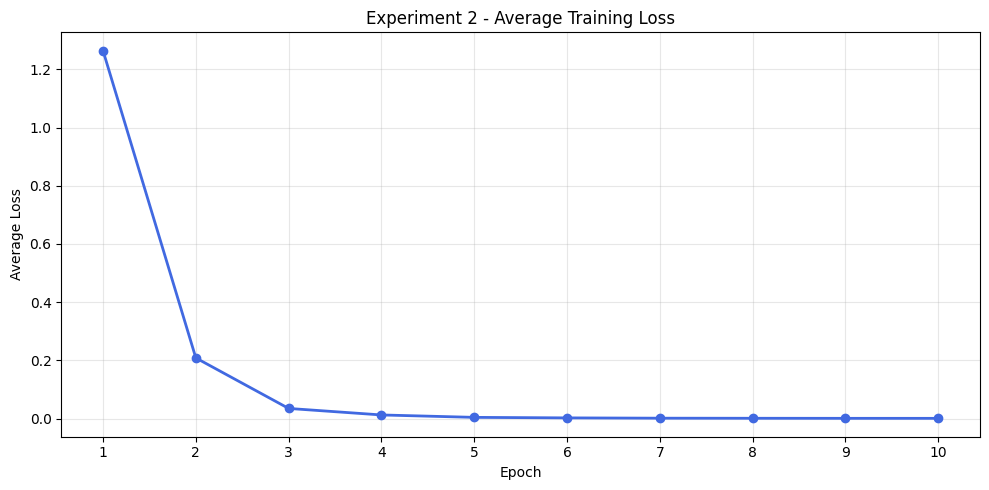

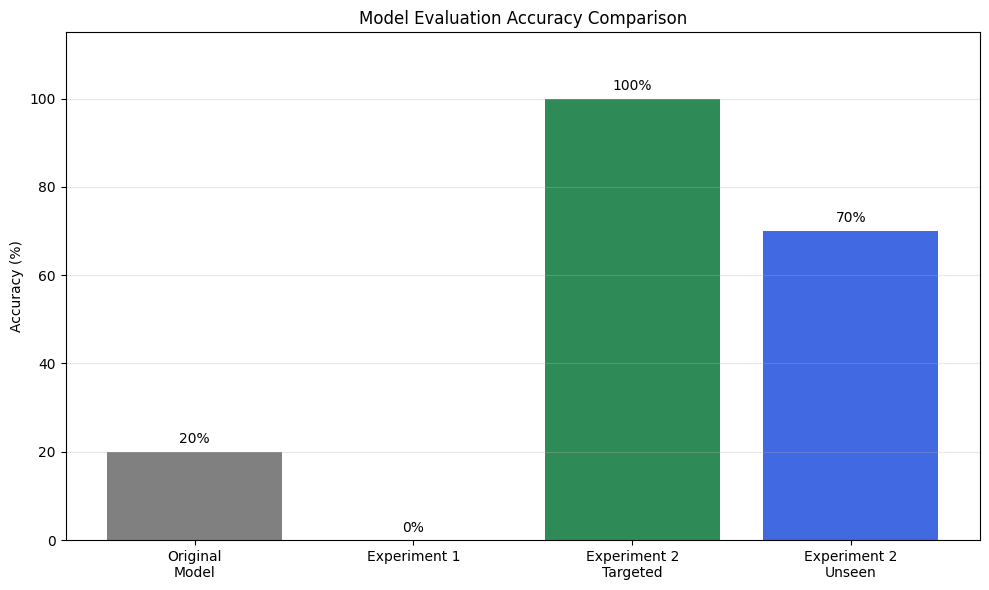


All final results saved successfully!
accuracy_comparison.png
checkpoints
computer_shop_qa_expanded.jsonl
experiment_summary.json
latest_adapter
lora_adapter
model_comparison.csv
training_history.csv
training_loss.png
unseen_evaluation.csv


In [32]:

import matplotlib.pyplot as plt
import pandas as pd
import json

# Record manually evaluated correctness
experiment_2_comparison["original_correct"] = [
    1, 0, 0, 0, 0
]

experiment_2_comparison["fine_tuned_correct"] = [
    1, 1, 1, 1, 1
]

unseen_comparison["correct"] = [
    1, 0, 0, 1, 0, 1, 1, 1, 1, 1
]

experiment_2_comparison.to_csv(
    EXPERIMENT_2_DIR / "model_comparison.csv",
    index=False
)

unseen_comparison.to_csv(
    EXPERIMENT_2_DIR / "unseen_evaluation.csv",
    index=False
)

# Graph 1: Training loss
epoch_losses = training_history.groupby("epoch")["loss"].mean()

plt.figure(figsize=(10, 5))
plt.plot(
    epoch_losses.index,
    epoch_losses.values,
    marker="o",
    color="royalblue",
    linewidth=2
)

plt.title("Experiment 2 - Average Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    EXPERIMENT_2_DIR / "training_loss.png",
    dpi=300
)

plt.show()

# Graph 2: Evaluation accuracy
labels = [
    "Original\nModel",
    "Experiment 1",
    "Experiment 2\nTargeted",
    "Experiment 2\nUnseen"
]

accuracies = [20, 0, 100, 70]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    labels,
    accuracies,
    color=["gray", "tomato", "seagreen", "royalblue"]
)

plt.bar_label(bars, fmt="%.0f%%", padding=4)

plt.title("Model Evaluation Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 115)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    EXPERIMENT_2_DIR / "accuracy_comparison.png",
    dpi=300
)

plt.show()

# Save final LoRA adapter and tokenizer
model.save_pretrained(
    EXPERIMENT_2_DIR / "lora_adapter"
)

tokenizer.save_pretrained(
    EXPERIMENT_2_DIR / "lora_adapter"
)

# Save experiment summary
summary = {
    "base_model": MODEL_NAME,
    "fine_tuning_method": "LoRA",
    "training_framework": "PyTorch",
    "original_dataset_size": 50,
    "expanded_dataset_size": 250,
    "trainable_parameters": 8683520,
    "trainable_percentage": 2.3437,
    "epochs": 10,
    "batch_size": 4,
    "learning_rate": 0.0002,
    "training_steps": 630,
    "training_duration_seconds": 168.44,
    "peak_gpu_memory_gb": 1.93,
    "average_training_loss": 0.1533,
    "final_epoch_loss": float(epoch_losses.iloc[-1]),
    "original_model_accuracy": 0.20,
    "experiment_1_accuracy": 0.00,
    "experiment_2_targeted_accuracy": 1.00,
    "experiment_2_unseen_accuracy": 0.70,
    "experiment_2_combined_accuracy": 0.80
}

with open(
    EXPERIMENT_2_DIR / "experiment_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\nAll final results saved successfully!")

for path in sorted(EXPERIMENT_2_DIR.iterdir()):
    print(path.name)


In [33]:

import shutil
from pathlib import Path

EXPORT_DIR = Path("/kaggle/working/Lab-04-Fine-Tuning")

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Create required directories
(EXPORT_DIR / "notebooks").mkdir(exist_ok=True)
(EXPORT_DIR / "dataset").mkdir(exist_ok=True)
(EXPORT_DIR / "results").mkdir(exist_ok=True)
(EXPORT_DIR / "screenshots").mkdir(exist_ok=True)

# Copy original dataset
shutil.copy2(
    EXPERIMENT_1_DIR / "computer_shop_qa.jsonl",
    EXPORT_DIR / "dataset"
)

# Copy expanded dataset
shutil.copy2(
    EXPERIMENT_2_DIR / "computer_shop_qa_expanded.jsonl",
    EXPORT_DIR / "dataset"
)

# Copy Experiment 1 results
shutil.copytree(
    EXPERIMENT_1_DIR,
    EXPORT_DIR / "results" / "experiment_1",
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns(
        "checkpoints",
        "computer_shop_qa.jsonl"
    )
)

# Copy Experiment 2 results
shutil.copytree(
    EXPERIMENT_2_DIR,
    EXPORT_DIR / "results" / "experiment_2",
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns(
        "checkpoints",
        "latest_adapter",
        "computer_shop_qa_expanded.jsonl"
    )
)

# Create ZIP archive
zip_path = shutil.make_archive(
    "/kaggle/working/Lab-04-Fine-Tuning",
    "zip",
    root_dir=EXPORT_DIR
)

print("Export completed successfully!")
print("ZIP file:", zip_path)
print(f"ZIP size: {Path(zip_path).stat().st_size / 1024**2:.2f} MB")

print("\nExported files:")

for path in sorted(EXPORT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(EXPORT_DIR))


Export completed successfully!
ZIP file: /kaggle/working/Lab-04-Fine-Tuning.zip
ZIP size: 63.82 MB

Exported files:
dataset/computer_shop_qa.jsonl
dataset/computer_shop_qa_expanded.jsonl
results/experiment_1/baseline_responses.csv
results/experiment_1/lora_adapter/README.md
results/experiment_1/lora_adapter/adapter_config.json
results/experiment_1/lora_adapter/adapter_model.safetensors
results/experiment_1/lora_adapter/merges.txt
results/experiment_1/lora_adapter/special_tokens_map.json
results/experiment_1/lora_adapter/tokenizer.json
results/experiment_1/lora_adapter/tokenizer_config.json
results/experiment_1/lora_adapter/vocab.json
results/experiment_1/model_comparison.csv
results/experiment_1/training_history.csv
results/experiment_1/training_loss.png
results/experiment_2/accuracy_comparison.png
results/experiment_2/experiment_summary.json
results/experiment_2/lora_adapter/README.md
results/experiment_2/lora_adapter/adapter_config.json
results/experiment_2/lora_adapter/adapter_model